# Raw EELS events to temperature maps

Converts one time-resolved EELS (EELS) acquisition, recorded as Timepix3 electron events, into a temperature-change map **ΔT(sx, sy, t)** of an aluminium nanobridge. The map is saved as a HyperSpy `.hspy` file. Step numbers follow the pipeline flowchart in the README.<br>
The design choices behind parameters are in `DESIGN_CHOICES.md`.

**Input:** raw acquisition folder (`meta_data_path`) or its preprocessed events (`output_data_path`) <br>
**Output:** `High - res Hyperspim - Temperatures.hspy` (plus the fit model and the plasmon-centre map)

**Sections**
- Setup
1. Preprocess
2. Build the coincidence object
3. Offset correction
4. Energy axis calibration
5. Pulse detection using PINEM

- Bulk plasmon pre-fit
- Aluminium mask preview

6. Crop and rebin
- 7---8. PCA and aluminium mask
9. Multifit: per-pixel fitting
10. Energy to temperature
11. Temperature model fitting (processed in another file)
- Optional: ΔT movie

## Setup

Requires `pytpx`, `hyperspy`, `numpy`, `scipy`, `matplotlib` and `ipympl` (for `%matplotlib widget`).

In [1]:
%matplotlib widget
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit
from scipy.signal import fftconvolve
import hyperspy.api as hs
import pytpx

## 1. Preprocess

Selects the events in the acquisition time window, builds the event list and computes the delay Δt between each laser pulse and the detected electron. This is slow, so run it once per acquisition and keep the cell commented out afterwards.

In [ ]:
# Folder for the preprocessed events (written by step 1, read by step 2)
output_data_path = r"output_data"
# Raw acquisition folder (data + metadata)
meta_data_path = r"meta_data"

In [3]:
# Run once per acquisition: raw events -> preprocessed event list
# sparse_data, matrix_data, meta = pytpx.preprocess.load(meta_data_path,energy_invers=False)
# pytpx.preprocess.save(output_data_path,sparse_data,matrix_data)

## 2. Build the coincidence object

Loads the preprocessed events into a `pytpx.CoincidenceEvents` object `ce` with axes (sx, sy, t, E).<br>
Steps 3 and 4 correct `ce` in place; later steps work on cropped or rebinned copies of it.

In [4]:
# Build the CoincidenceEvents object from the preprocessed events
ce = pytpx.CoincidenceEvents.load(
    data_path= output_data_path,
    meta_path= meta_data_path
)

## 3. Offset correction

Due to an offset in the detector, the spectra drift from the left of the scan window to the right.<br>
Left uncorrected, this drift would show up as a false plasmon energy shift. Each pixel's spectrum is cross-correlated with a reference spectrum from the scan centre, and the resulting offset is subtracted from the energy channel of every event.

In [5]:
# Spectrum image (SPIM) before correction
ce.spim.plot()

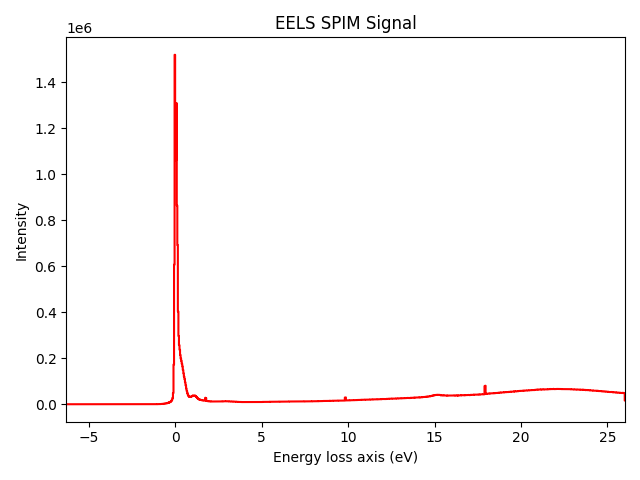

In [ ]:
# Reference spectrum: crop the central 8 x 8 pixels and rebin them into one spectrum
sx_len = ce.shape["sx"]
sy_len =  ce.shape["sy"]
crop_window = 8
ce_crop_spim  = ce.crop(
    [
        ("sx",sx_len/2 - crop_window/2  ,sx_len/2 + crop_window/2 ),
        ("sy",sy_len/2 - crop_window/2  ,sy_len/2 + crop_window/2 )
    ]
)
ce_crop_spim = ce_crop_spim.rebin([
    ("sx",8),
    ("sy",8)
])
reference_eels = ce_crop_spim.spim.inav[0,0]

reference_eels.plot()

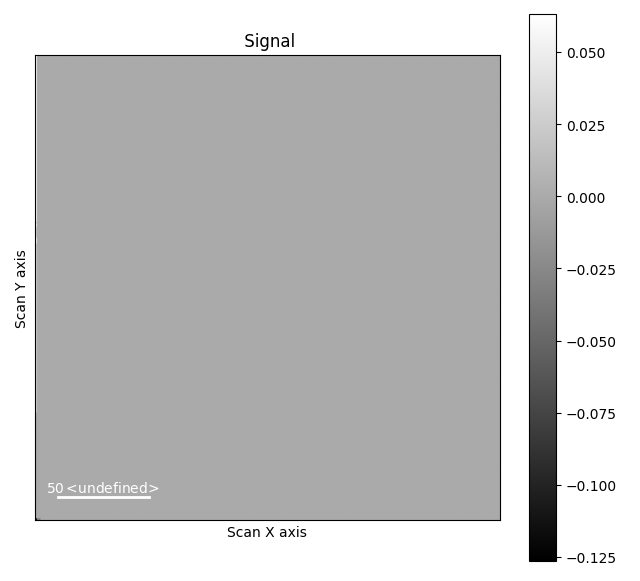

In [ ]:
# Cross-correlate the reference with every pixel's spectrum (FFT, all pixels at once)
spim_full = ce.spim

reference_data = reference_eels.data  # shape (1025,)
energy_scale = spim_full.axes_manager["Energy loss"].scale

# Flip reference for cross-correlation
ref_flipped = reference_data[::-1]

# Cross-correlate all spectra at once
cross_corr = fftconvolve(spim_full.data, ref_flipped[np.newaxis, np.newaxis, :], mode='full', axes=-1)

# Position of the correlation peak -> offset per pixel, in channels and in eV
shift_idx = np.argmax(cross_corr, axis=-1)  # shape (256, 256)
offset_channels = shift_idx - (len(reference_data) - 1)
offset_eV = offset_channels * energy_scale



# Offset map as a HyperSpy signal, for inspection
offset_map = hs.signals.Signal2D(offset_eV)
offset_map.axes_manager[0].scale = spim_full.axes_manager[0].scale
offset_map.axes_manager[1].scale = spim_full.axes_manager[1].scale
offset_map.axes_manager[0].name = "Scan X"
offset_map.axes_manager[1].name = "Scan Y"
offset_map.plot()

### Apply the offset to every event

In [ ]:
# Look up the offset of each event's pixel (offset map is indexed [sy, sx])
events = ce._events_dict()
offset_ce_ordered_array = offset_channels[events["sy"],events["sx"]]
offset_ce_ordered_array = np.array(offset_channels[events["sy"],events["sx"]],dtype="float")
# Subtract, clip to the detector channel range (0-1023) and convert back to uint16
e_corrected  = events["e"] - offset_ce_ordered_array
e_corrected = np.clip(e_corrected,0,1023)
e_corrected  = np.array(e_corrected, dtype="uint16")

In [9]:
ce.e = e_corrected

### Check the correction

The same procedure on the corrected data. The offset map should now be close to zero everywhere.

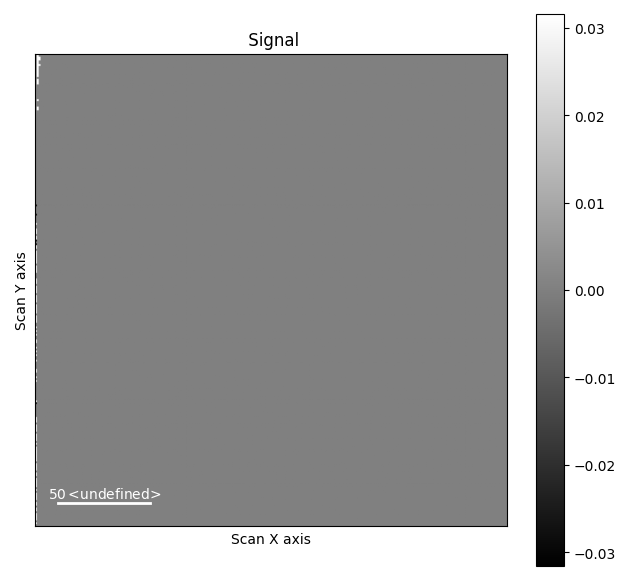

In [ ]:
# Reference spectrum from the corrected data
sx_len = ce.shape["sx"]
sy_len =  ce.shape["sy"]
crop_window = 8
ce_crop_spim  = ce.crop(
    [
        ("sx",sx_len/2 - crop_window/2  ,sx_len/2 + crop_window/2 ),
        ("sy",sy_len/2 - crop_window/2  ,sy_len/2 + crop_window/2 )
    ]
)
ce_crop_spim = ce_crop_spim.rebin([
    ("sx",8),
    ("sy",8)
])
reference_eels = ce_crop_spim.spim.inav[0,0]

#reference_eels.plot()



# Recompute the SPIM from the corrected events
ce.calculate_coincidence_spim()
spim_full = ce.coincidence_spim

reference_data = reference_eels.data  # shape (1025,)
energy_scale = spim_full.axes_manager["Energy loss"].scale

# Flip reference for cross-correlation
ref_flipped = reference_data[::-1]

# Cross-correlate all spectra at once
cross_corr = fftconvolve(spim_full.data, ref_flipped[np.newaxis, np.newaxis, :], mode='full', axes=-1)

# Find peak shift for each pixel
shift_idx = np.argmax(cross_corr, axis=-1)  # shape (256, 256)
offset_channels = shift_idx - (len(reference_data) - 1)
offset_eV = offset_channels * energy_scale


# Residual offset map (should be ~0)
offset_map = hs.signals.Signal2D(offset_eV)
offset_map.axes_manager[0].scale = spim_full.axes_manager[0].scale
offset_map.axes_manager[1].scale = spim_full.axes_manager[1].scale
offset_map.axes_manager[0].name = "Scan X"
offset_map.axes_manager[1].name = "Scan Y"
offset_map.plot()

## 4. Energy axis calibration

While the laser is on, PINEM sidebands appear at ±ħω around the zero-loss peak (ZLP). For a 550 nm laser, ħω ≈ 2.25 eV. Fitting the two first-order sidebands gives:
- the **dispersion** (eV per channel), from their separation;
- the **energy offset**, from their midpoint. The ZLP is then placed at 0 eV.

The crop windows and fit guesses below are set per dataset.

In [7]:
# Axis value -> channel index
def val_2_index(axis,value):
    return int((value - axis.offset) / axis.scale)

In [ ]:
# Expected sideband position: photon energy E = hc / wavelength
Wavelength_photon = 550 #nm

energy_photon = (4.1356677*1e-15)*2.9979246*1e8/(Wavelength_photon*1e-9)
energy_photon = np.round(energy_photon,6)

print(f"Photon's theoretical energy {energy_photon}eV") # theoretical energy of the PINEM peaks from 0

Photon's theoretical energy 2.254258eV


In [ ]:
# t-E histogram around the +ħω sideband, used to choose the crop windows below
ce_crop_cal_r = ce.crop( [
        ("e",1.9, 2.5),
        ("t",2540.0,2590.0)
    ])
ce_crop_cal_r.calculate_te_histogram()

ce_crop_cal_r.te_histogram.plot()

In [10]:
# Crop to the +ħω (right, energy loss) and -ħω (left, energy gain) sidebands during the pulse
ce_crop_cal_r = ce.crop(     [
        ("e",1.9, 2.5),
         ("t",2540.0,2590.0)
    ]
    )
ce_crop_cal_l = ce.crop( [
        ("e",-2.6,-1.80),
        ("t",2540.0,2590.0)
    ])
# Sum over time -> one spectrum per sideband
ce_crop_cal_r.calculate_te_histogram()
pinem_r = ce_crop_cal_r.te_histogram.sum(axis=["Time Delay"])

ce_crop_cal_l.calculate_te_histogram()
pinem_l = ce_crop_cal_l.te_histogram.sum(axis=["Time Delay"])

# Full coincidence spectrum (its energy axis is used below)
ce.calculate_coincidence_spectrum()
ce_master = ce.coincidence_spectrum

In [ ]:
def fit_pinem_calib(pinem_signal:object,guess_centre:float,guess_centre_range:list):
    """Fit one PINEM sideband with a Gaussian + linear background.

    Returns the Gaussian centre in eV. The centre is bounded to guess_centre_range.
    """
    model_fit_pinem = pinem_signal.create_model()
    lorentz_fit_dummy = hs.model.components1D.Gaussian()  # Gaussian component

    lorentz_fit_dummy.centre.value = guess_centre

    lorentz_fit_dummy.centre.bmin = guess_centre_range[0]
    lorentz_fit_dummy.centre.bmax = guess_centre_range[1]


    linear_bg_dummy = hs.model.components1D.Polynomial(order=1)

    model_fit_pinem.append(lorentz_fit_dummy)
    model_fit_pinem.append(linear_bg_dummy)

    model_fit_pinem.fit(bounded = True)

    model_fit_pinem.plot(plot_components = False)
    return lorentz_fit_dummy.centre.value

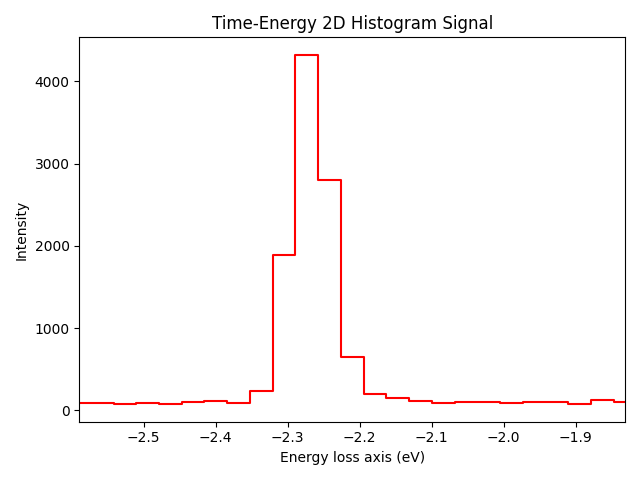

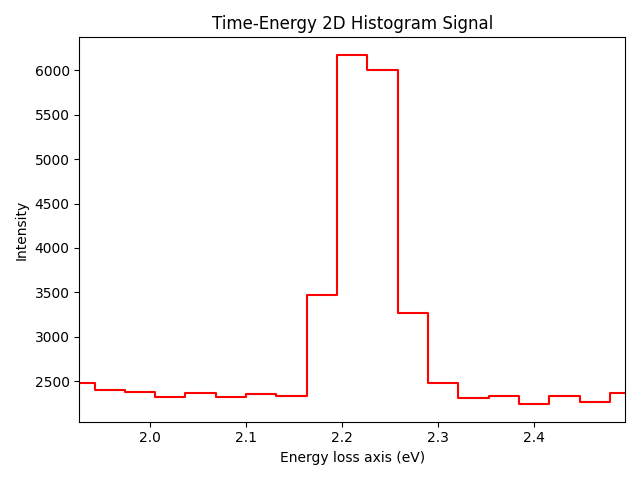

PINEM fit for left peak : -2.241876898104775 eV
PINEM fit for right peak : 2.224869595630662 eV 

Dispersion before callibration : 31.576 meV/px
Dispersion before callibration : 31.679053147059836 meV/px
Relative change = 0.010305314705983531 % 

Energy offset before callibration : -6.3152 eV
Relative energy offset  required : -0.008503651237056431 eV
Energy offset after callibration : -6.3066963487629435 eV


In [12]:
# Fit both sidebands (guess and bounds in eV, set per dataset)
pinem_l_centre = fit_pinem_calib(pinem_l,-2.27,[-2.4,-2.1])
pinem_r_centre = fit_pinem_calib(pinem_r,2.22,[2.0,2.4])

# Dispersion = sideband separation in eV / separation in channels
pixels_pinem_lr = val_2_index(ce_master.axes_manager["Energy loss"],pinem_r_centre) - val_2_index(ce_master.axes_manager["Energy loss"],pinem_l_centre)
energy_pinem_lr = (pinem_r_centre -pinem_l_centre)

# Energy per pixel calibration
energy_scale_pinem_calib = energy_pinem_lr/pixels_pinem_lr
print(f"PINEM fit for left peak : {pinem_l_centre} eV")
print(f"PINEM fit for right peak : {pinem_r_centre} eV \n")

print(f"Dispersion before callibration : {ce.axes.axis_e.scale*1e3} meV/px")
print(f"Dispersion before callibration : {energy_scale_pinem_calib*1e3} meV/px")
print(f"Relative change = {abs(energy_scale_pinem_calib - ce.axes.axis_e.scale)*100} % \n")

# Apply the new dispersion to ce
ce.axes.axis_e.scale  =  energy_scale_pinem_calib

# Energy offset: midpoint of the two sidebands, moved to 0 eV (ZLP calibration)
offset_PINEM_ZLP = ((pinem_l_centre + pinem_r_centre))/2
print(f"Energy offset before callibration : {ce.axes.axis_e.offset} eV")
print(f"Relative energy offset  required : {offset_PINEM_ZLP} eV")


ce.axes.axis_e.offset -= offset_PINEM_ZLP
print(f"Energy offset after callibration : {ce.axes.axis_e.offset} eV")

### Check the calibration

The dispersion should change only slightly (fine-tuning, not a new calibration), and the ZLP should sit at about 0 eV.

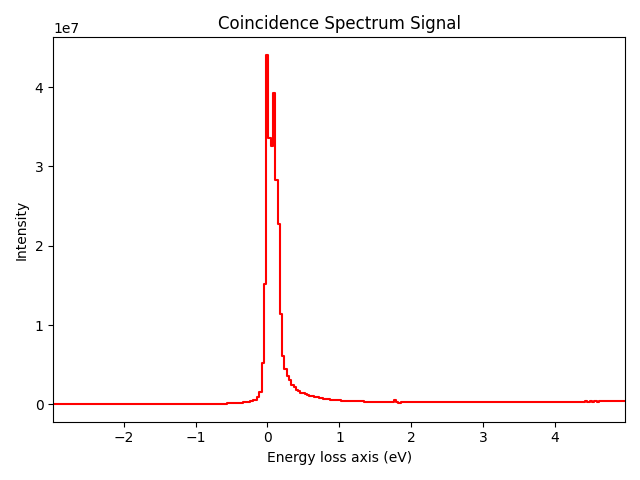

In [ ]:
# Coincidence spectrum around the ZLP: the peak should be at ~0 eV
ce_crop_dummy = ce.crop(
    [
        ("e",-3.0,5.0)
    ]
)
ce_crop_dummy.calculate_coincidence_spectrum()
ce_crop_dummy.coincidence_spectrum.plot()

Re-fit the sidebands on the calibrated axis. They should sit at ±ħω, symmetric about 0 eV.

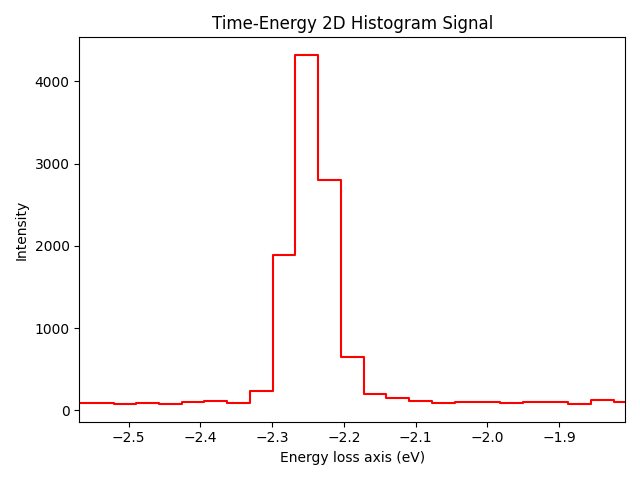

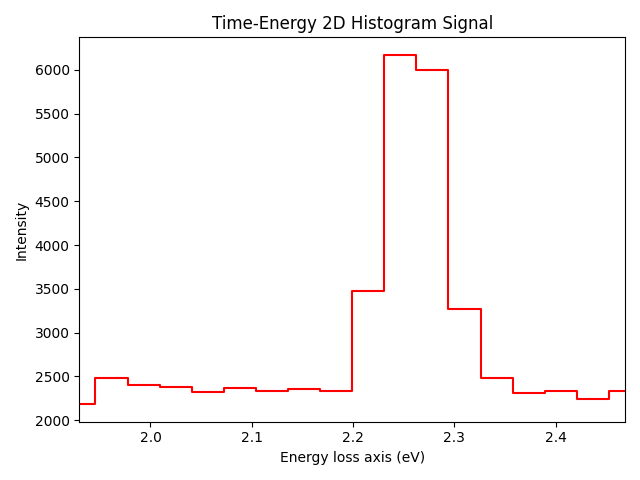

Energy of left PINEM - -2.2518266518981247 eV
Energy of right PINEM - 2.261244440047041 eV
Energy difference - 9.417788148916362 meV


In [14]:
# Re-fit both sidebands on the calibrated energy axis
ce_crop_cal_r = ce.crop(     [
        ("e",1.9, 2.5),
         ("t",2540.0,2590.0)
    ]
    )
ce_crop_cal_l = ce.crop( [
        ("e",-2.6,-1.80),
        ("t",2540.0,2590.0)
    ])
ce_crop_cal_r.calculate_te_histogram()
pinem_r = ce_crop_cal_r.te_histogram.sum(axis=["Time Delay"])

ce_crop_cal_l.calculate_te_histogram()
pinem_l = ce_crop_cal_l.te_histogram.sum(axis=["Time Delay"])

energy_pinem_l = fit_pinem_calib(pinem_l,-2.0,[-2.5,-1.0])
energy_pinem_r = fit_pinem_calib(pinem_r,2.0,[1.8,2.3])

print(f"Energy of left PINEM - {energy_pinem_l} eV")
print(f"Energy of right PINEM - {energy_pinem_r} eV")
# Asymmetry (right + left) in meV, should be ~0
print(f"Energy difference - {(energy_pinem_r + energy_pinem_l)*1e3} meV")

### Overview: calibrated t-E histogram

In [ ]:
# Full time-energy histogram after offset correction and calibration
ce.calculate_te_histogram()
ce.te_histogram.plot()

## 5. Pulse detection using PINEM

We use the PINEM sideband as a laser clock: it exists only while the laser is on, so its intensity over time traces the pulse.<br>
The delay spectrum of the -ħω sideband is smoothed with a polynomial fit. The first and last zero crossings of its second derivative give `time_laser_on` and `time_laser_off`.

Set `initial_time_slice` per dataset. In the plot, check that the green and red lines sit on the pulse edges.

In [15]:
input_laser_energy = energy_pinem_lr/2 # ħω from the calibrated sideband separation
initial_time_slice = [2530.0,2590.0] # rough window around the pulse in ns (floats, set per dataset)
poly_order = 12  # order of the polynomial used to smooth the PINEM trace

In [16]:
def PINEM_time(input_laser_eV:float, rough_time_slice:list, poly_order_fit:int, fit_plot :bool=False):
    """Detect the laser pulse from the PINEM sideband intensity over time.

    Returns (time_laser_on, time_laser_off) in ns. fit_plot=True shows the trace, fit and edges.
    """
    # Crop to the -ħω sideband (±0.5 eV) inside the rough time window
    ce_crop = ce.crop([
        ("e", -(input_laser_eV + 0.5), -(input_laser_eV - 0.5)),
        ("t", rough_time_slice[0], rough_time_slice[1])
    ])
    # Sideband intensity vs. time
    ce_crop.calculate_delay_spectrum()
    t_hist_PINEM = ce_crop.delay_spectrum
    time_axis = t_hist_PINEM.axes_manager[0].axis

    # Smooth the trace with a polynomial fit
    model_fit = t_hist_PINEM.create_model()
    poly = hs.model.components1D.Polynomial(order=poly_order_fit)
    model_fit.append(poly)
    model_fit.fit()
    # converting model_fit object to data
    m_signal = model_fit.as_signal()
    m_signal.metadata.General.title = f"PINEM delay spectrum - Polynomial^{poly_order_fit} fit"
    m_signal = m_signal.data

    # First and second derivatives of the fit
    d_model = np.gradient(m_signal, time_axis)
    d2_model = np.gradient(d_model,time_axis)

    # Pulse edges: first and last sign change of the second derivative
    zero_crossing = np.where(np.diff(np.sign(d2_model)))[0]
    crossing_times = time_axis[zero_crossing]
    time_laser_on = crossing_times[0]
    time_laser_off = crossing_times[-1]

    # Alternative (not used): steepest rise and fall
    # time_laser_on = time_axis[np.argmax(d_model)]
    # time_laser_off = time_axis[np.argmin(d_model)]

    if fit_plot:
        fig, ax = plt.subplots()
        ax.scatter(time_axis, t_hist_PINEM.data, label="PINEM raw", s=10, color="orange")
        ax.plot(time_axis, m_signal, label="Polynomial fit")
        ax.plot(time_axis, d_model / d_model.max() * 0.5 * t_hist_PINEM.data.max(), label="Derivative (scaled)")
        ax.axvline(time_laser_on, color="green", linestyle="--", label=f"laser_on: {time_laser_on:.2f} ns")
        ax.axvline(time_laser_off, color="red", linestyle="--", label=f"laser_off: {time_laser_off:.2f} ns")
        ax.set_xlabel("Time (ns)")
        ax.set_ylabel("Intensity")
        ax.set_title(f"PINEM delay spectrum - Polynomial^{poly_order_fit} fit")
        ax.legend()
        plt.tight_layout()
        plt.show()

    return time_laser_on, time_laser_off

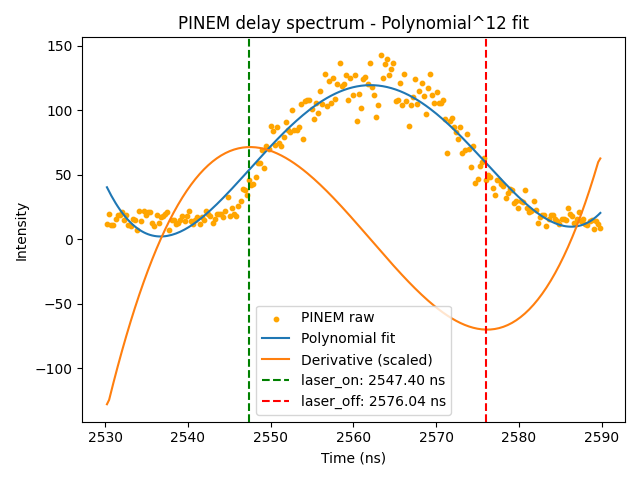

time_laser_on - 2547.3958333333335 ns
time_laser_off - 2576.041666666667 ns
pulse_width  - 28.645833333333485 ns


In [17]:
# Detect the pulse and check the plot
time_laser_on, time_laser_off = PINEM_time(input_laser_eV = input_laser_energy,rough_time_slice = initial_time_slice,poly_order_fit=poly_order,fit_plot=True)


print(f"time_laser_on - {time_laser_on} ns")
print(f"time_laser_off - {time_laser_off} ns")
print(f"pulse_width  - {time_laser_off-time_laser_on} ns")

## Bulk plasmon pre-fit

Fits the Al bulk plasmon (about 15 eV) before PCA, to get starting values for the per-pixel fit in step 9:
1. `fit_bulk_plasmon`: the spectrum summed over all pixels and time, fitted with a Lorentzian and a linear background.
2. `multifit_te_plot`: the t-E histogram fitted frame by frame, starting from the result of 1.

In [ ]:
def fit_bulk_plasmon(bulk_plasmon_centre:float,energy_window_bulk_plasmon:float, plot_fit :bool = False,fit_before_PINEM:bool = False):
    """Fit the bulk plasmon in the spectrum summed over all pixels and time.

    Returns (Lorentzian centre, Lorentzian gamma, cropped CoincidenceEvents object).
    """

    bulk_plasmon_centre = float(bulk_plasmon_centre)
    energy_window_bulk_plasmon = float(energy_window_bulk_plasmon)
    # determine the Laser on-off time
    time_laser_on, time_laser_off = PINEM_time(input_laser_eV = input_laser_energy,rough_time_slice = initial_time_slice,poly_order_fit=poly_order,fit_plot=False)

    # Time window: before the pulse (fit_before_PINEM=True) or around and after it
    if fit_before_PINEM:
        time_crop_tuple =  ("t", 20.0 ,time_laser_on - time_laser_on*0.4)
    else:
        time_crop_tuple = ("t", time_laser_on-time_laser_on*0.1,time_laser_off+time_laser_off*0.8)

    # Crop t and E around the plasmon
    ce_crop_bulk = ce.crop(
    [
        time_crop_tuple,
        ("e",bulk_plasmon_centre - energy_window_bulk_plasmon ,  bulk_plasmon_centre+energy_window_bulk_plasmon)
    ]
    )

    # Sum into a single spectrum
    ce_crop_bulk.calculate_te_histogram()
    summed_bulk = ce_crop_bulk.te_histogram.sum()
    time_axis = summed_bulk.axes_manager[0].axis 

    # Lorentzian (plasmon) + linear background
    model_fit = summed_bulk.create_model()
    lorentzian_fit = hs.model.components1D.Lorentzian()
    model_fit.append(lorentzian_fit)

    # Fit a linear background offset to the data
    offset_linear = hs.model.components1D.Polynomial(order=1)
    model_fit.append(offset_linear)

    # Bounds: centre inside the energy window, gamma 0.01-2 eV
    lorentzian_fit.centre.bmin = bulk_plasmon_centre - energy_window_bulk_plasmon
    lorentzian_fit.centre.bmax = bulk_plasmon_centre + energy_window_bulk_plasmon
    lorentzian_fit.gamma.bmin = 0.01
    lorentzian_fit.gamma.bmax = 2.0

    model_fit.fit(bounded = True)
    lorentz_centre = lorentzian_fit.centre.value # Lorentzian centre
    lorentz_std = lorentzian_fit.gamma.value # Lorentzian gamma (half width at half maximum)

    m_signal = model_fit.as_signal()
    m_signal.metadata.General.title = "Bulk plasmon - Lorentizian fit"
    m_signal = m_signal.data

    if plot_fit:
        fig, ax = plt.subplots()
        ax.scatter(time_axis, summed_bulk.data, label="Bulk plasmon - raw", s=10, color="orange")
        ax.plot(time_axis, m_signal, label="Lorentzian fit")
        ax.set_xlabel("Energy (eV)")
        ax.set_ylabel("Intensity")
        ax.set_title(f"Bulk plasmon spectrum - Lorentzian fit")
        ax.legend()
        plt.tight_layout()
        plt.show()

    return lorentz_centre, lorentz_std , ce_crop_bulk

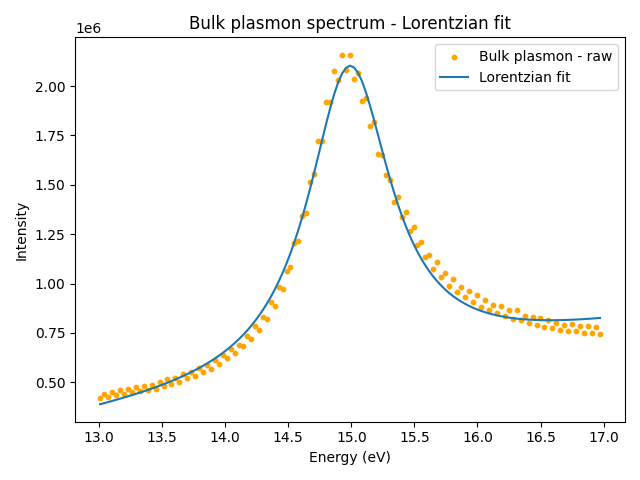

(14.985225894323587,
 0.40130658273047115,
 <pytpx.analysis.coincidence.events.CoincidenceEvents at 0x265417b45f0>)

In [37]:
# Summed fit: plasmon guess 15 eV, energy window ±2 eV
fit_bulk_plasmon(15.0,2.0,plot_fit=True)

In [38]:
def multifit_te_plot(bulk_plasmon_centre:float,energy_window_bulk_plasmon:float,plot_fit_centre_gamma:bool = False, plot_multifit :bool = False):
    """Fit the bulk plasmon in every time frame of the t-E histogram.

    Starts from the summed fit (fit_bulk_plasmon). Returns the HyperSpy model.
    """


    bulk_plasmon_centre = float(bulk_plasmon_centre)
    energy_window_bulk_plasmon = float(energy_window_bulk_plasmon)

    # Starting values from the summed fit
    bulk_peak_centre, bulk_peak_std , ce_crop_bulk = fit_bulk_plasmon(bulk_plasmon_centre,energy_window_bulk_plasmon)
    te_hist = ce_crop_bulk.te_histogram

    # Lorentzian + linear background, started from the summed fit
    model_fit_te = te_hist.create_model()
    lorentz_fit = hs.model.components1D.Lorentzian()
    linear_bg = hs.model.components1D.Polynomial(order=1)


    lorentz_fit.centre.value = bulk_peak_centre
    lorentz_fit.gamma.value = bulk_peak_std
    lorentz_fit.centre.bmin = bulk_peak_centre - energy_window_bulk_plasmon
    lorentz_fit.centre.bmax = bulk_peak_centre + energy_window_bulk_plasmon
    lorentz_fit.gamma.bmax = 1.0
    lorentz_fit.gamma.bmin = 0.01



    model_fit_te.append(lorentz_fit)
    model_fit_te.append(linear_bg)

    # One fit per time frame
    model_fit_te.multifit( bounded = True)

    if plot_multifit:
      model_fit_te.plot(plot_components=True)
    if plot_fit_centre_gamma:
       lorentz_fit.centre.as_signal().plot()
       lorentz_fit.gamma.as_signal().plot()


    return model_fit_te

  0%|          | 20/9002 [00:01<10:21, 14.45it/s] 

WARNING | Hyperspy | `m.fit()` did not exit successfully. Reason:  (hyperspy.model:2388)


  0%|          | 41/9002 [00:03<08:36, 17.36it/s]

WARNING | Hyperspy | `m.fit()` did not exit successfully. Reason:  (hyperspy.model:2388)
WARNING | Hyperspy | `m.fit()` did not exit successfully. Reason:  (hyperspy.model:2388)


  1%|          | 48/9002 [00:05<18:27,  8.09it/s]

WARNING | Hyperspy | `m.fit()` did not exit successfully. Reason:  (hyperspy.model:2388)


  1%|          | 54/9002 [00:06<22:28,  6.63it/s]

WARNING | Hyperspy | `m.fit()` did not exit successfully. Reason:  (hyperspy.model:2388)


  1%|          | 59/9002 [00:07<23:42,  6.29it/s]

WARNING | Hyperspy | `m.fit()` did not exit successfully. Reason:  (hyperspy.model:2388)


100%|██████████| 9002/9002 [02:56<00:00, 51.11it/s]
path\to\python_env\Lib\site-packages\hyperspy\drawing\utils.py:161: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig = plt.figure(**kwargs)


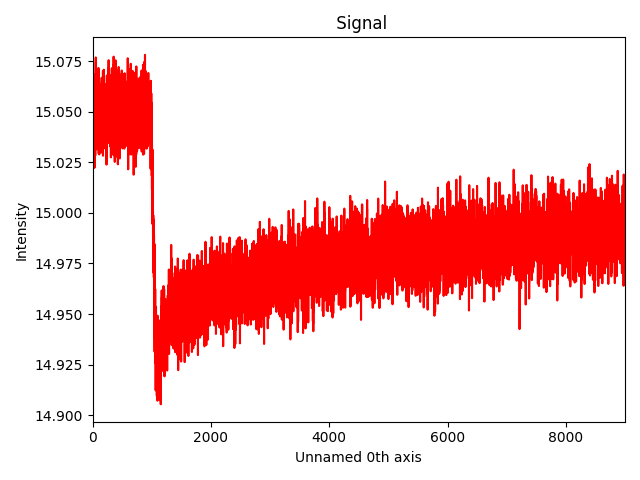

In [39]:
# Frame-by-frame fit; its first frame seeds the per-pixel fit in step 9
multifit_te_hist = multifit_te_plot(15.0,2.0)
# Plot centres of lorentzian
centers_multifit = hs.signals.Signal1D(multifit_te_hist.components.Lorentzian.parameters[1].map["values"])
centers_multifit.plot()

## Aluminium mask preview

A quick visual check of the masking idea used in step 8. Pixels whose 10-18 eV (plasmon) intensity is above 25 % of the maximum are kept. Nothing from this section is used later.

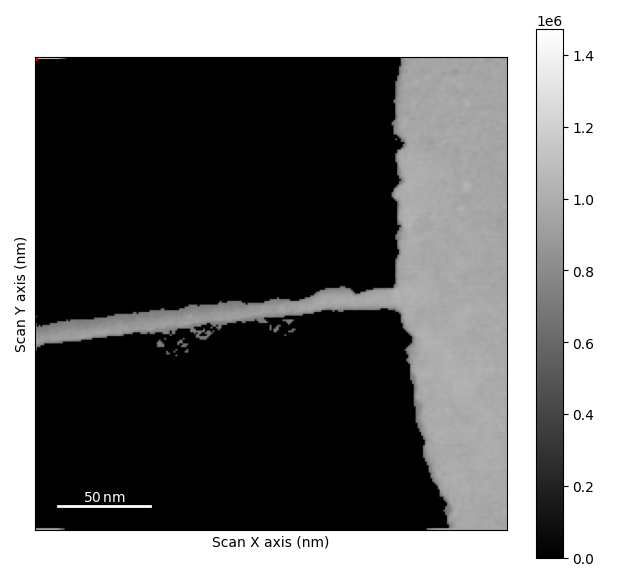

In [27]:
# Plasmon intensity map: SPIM summed over 10-18 eV
spim = ce.spim
spim_sum = spim.isig[10.0:18.0].sum(axis=2)

# Keep pixels above 25 % of the maximum
threshold = 0.25*spim_sum.data.max()
mask = spim_sum.data > threshold

# Masked intensity map
spim_masked = spim.data* mask[:,:,np.newaxis]
spim_masked_hs = hs.signals.Signal1D(spim_masked)
spim_masked_hs.axes_manager = spim.axes_manager
(spim_masked_hs).sum(axis=-1).plot()
# Dummy path: set to your own figures folder
plt.savefig(r"path/to/figures/after-mask.pdf",dpi=300)

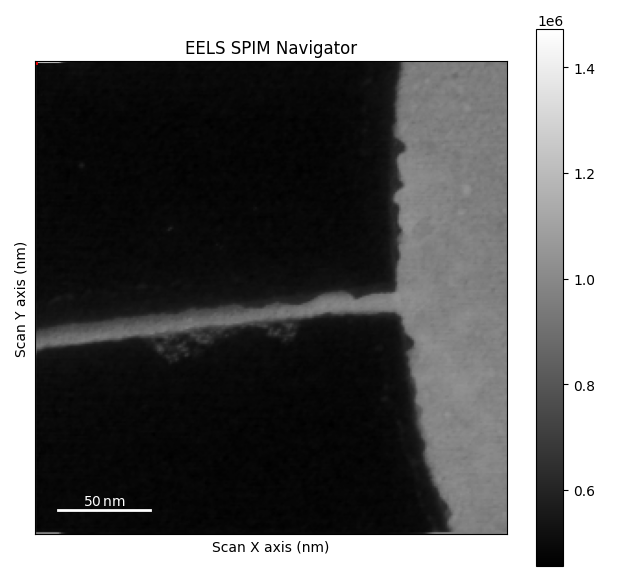

In [20]:
# Unmasked intensity map, for comparison
spim.sum(axis=-1).plot()

# Dummy path: set to your own figures folder
plt.savefig(r"path/to/figures/no-mask.pdf",dpi=300)

## 6. Crop and rebin

We only need the bulk plasmon and the time after the pulse, so `ce` is cropped to that region and then rebinned for counting statistics.

| Axis | Crop | Rebin |
|---|---|---|
| t  | from `0.8 * t_on`, 2^13 + 2^11 + 2^10 = 11264 channels | x8 |
| E  | from 12 eV, 2^8 = 256 channels | x2 |
| sx | full | x8 |
| sy | full | x8 |

The window starts before `t_on`, so the first frames give the pre-laser reference used in step 10.<br>
For scan 02 the shape goes from (t, E, sx, sy) = (11264, 256, 256, 256) to (1408, 128, 32, 32).

In [40]:
# te_histogram is computed here for its axes (value -> index conversion)
ce.calculate_te_histogram()
# Time window: from 0.8 * t_on, 2^13 + 2^11 + 2^10 channels
time_start_indx = val_2_index(ce.te_histogram.axes_manager["Time Delay"],time_laser_on-time_laser_on*0.2)
time_end_indx = time_start_indx+ +2**13 + 2**11 + 2**10
# Energy window: from 12 eV, 2^8 channels
energy_start_indx = val_2_index(ce.te_histogram.axes_manager["Energy loss"],12.0)
energy_end_indx = energy_start_indx+2**8

# Crop with channel indices (ints)
ce_crop_hyperspim = ce.crop(
        [
        ("t",time_start_indx,time_end_indx),
        ("e",energy_start_indx, energy_end_indx)
    ]
    )
print(f"Before rebining - {ce_crop_hyperspim.shape}")
ce_rebin_hyperspim = ce_crop_hyperspim.rebin(
    [
        ("t",8),
        ("sx",8),
        ("sy",8),
        ("e",2)
    ]
)
print(f"After rebining - {ce_rebin_hyperspim.shape}")

Before rebining - {'t': 11264, 'e': 256, 'sx': 256, 'sy': 256}
After rebining - {'t': 1408, 'e': 128, 'sx': 32, 'sy': 32}


## 7-8. PCA and aluminium mask

`masked_PCA_hyperspim`:
- builds the 4D `te_hyperspim` (sx, sy, t, E), runs PCA (`sklearn_pca`) and reconstructs it from the first 10 components;
- masks the non-aluminium pixels. A pixel is kept if the maximum of its time-summed spectrum is above `threshold_factor` (25 %) of the global maximum.

## 9. Multifit: per-pixel fitting

`masked_multifit_PCA_hyperspim` moves the energy axis to the signal axis, so the navigation axes are (sx, sy, t). It then fits a Lorentzian and a linear background to every masked pixel and time frame.<br>
The starting values come from the first frame of the bulk plasmon pre-fit.

Runtime: about 1.5 h for scan 02 (32 x 32 pixels x 1408 frames).

In [41]:
def masked_PCA_hyperspim(ce_rebin_hyperspim_object : object, threshold_factor:float = 0.25):
    """Steps 7-8: PCA-denoise the hyperspim and mask the non-aluminium pixels.

    Returns (masked PCA-reconstructed signal, 4D boolean mask, True = aluminium).
    """

    # 4D hyperspim (sx, sy, t, E)
    ce_rebin_hyperspim_object.calculate_te_hyperspim()
    energy_filtered = ce_rebin_hyperspim_object.te_hyperspim

    # PCA (decomposition needs float data)
    energy_filtered.change_dtype("float64")
    energy_filtered.decomposition(algorithm="sklearn_pca")

    # To choose the number of components, check the scree plot:
    # energy_filtered.plot_explained_variance_ratio(n=20)

    # Reconstruct from the first 10 components
    pca_reconstructed = energy_filtered.get_decomposition_model(10)

    # Mask: keep pixels whose time-summed spectrum peaks above threshold_factor * global maximum
    coin_spim = pca_reconstructed.sum(axis=["Time Delay"])
    mask_initial = np.zeros(np.shape(coin_spim.data)[0:2],dtype="bool")

    threshold_hyperspim = threshold_factor* coin_spim.data.max()

    for sx_ind in range(np.shape(coin_spim.data)[0]):
        for sy_ind in range(np.shape(coin_spim.data)[1]):
            mask_initial[sx_ind,sy_ind] = threshold_hyperspim < (coin_spim.data[sx_ind,sy_ind]).max()

    # Broadcast the 2D mask to the 4D data shape
    mask_4d = np.broadcast_to(mask_initial[:,:,np.newaxis,np.newaxis], np.shape(energy_filtered)).copy().astype(bool)

    # Masked reconstruction (non-aluminium pixels set to 0)
    masked_hyperspim_hs = hs.signals.Signal2D(pca_reconstructed*mask_4d)
    masked_hyperspim_hs.axes_manager = pca_reconstructed.axes_manager

    return masked_hyperspim_hs , mask_4d



def masked_multifit_PCA_hyperspim(masked_hyperspim_hs_PCA_object:object,
                           mask_hyper_spim :list,
                           lorentz_centre : float = multifit_te_hist.components.Lorentzian.parameters[1].map["values"][0],
                           lorentz_std :float = multifit_te_hist.components.Lorentzian.parameters[2].map["values"][0],
                           ):
    """Step 9: fit the bulk plasmon in every masked pixel and time frame.

    Default lorentz_centre and lorentz_std are the first-frame values of the pre-fit
    (multifit_te_hist). They are read when this cell runs, so run the pre-fit first.
    Returns the fitted HyperSpy model.
    """

    # Energy as signal axis, navigation (sx, sy, t)
    masked_hyperspim_hs_PCA_T =  masked_hyperspim_hs_PCA_object.transpose(signal_axes=["Energy loss"]).rollaxis(0,2)

    # Lorentzian + linear background
    model_spim = masked_hyperspim_hs_PCA_T.create_model()
    lorentz_fit_spim = hs.model.components1D.Lorentzian()
    linear_bg = hs.model.components1D.Polynomial(order=1)


    lorentz_fit_spim.centre.value = lorentz_centre
    lorentz_fit_spim.gamma.value = lorentz_std


    # Bounds: centre ±20 %, gamma ±80 %
    lorentz_fit_spim.centre.bmin = lorentz_centre*(1 - 0.2)
    lorentz_fit_spim.centre.bmax = lorentz_centre*(1 + 0.2)
    lorentz_fit_spim.gamma.bmax = lorentz_std*(1 + 0.8)
    lorentz_fit_spim.gamma.bmin =lorentz_std*(1 - 0.8)

    model_spim.append(lorentz_fit_spim)
    model_spim.append(linear_bg)

    # Optional: start the fit at a chosen pixel
    #model_spim.axes_manager.indices = ( 4,2,22)

    # HyperSpy skips pixels where the mask is True, so pass the inverted aluminium mask
    model_spim.multifit(mask = ~mask_hyper_spim[:,:,:,0].transpose(2,0,1) ,iterpath = "serpentine",bounded=True,show_progressbar = True)

    return model_spim

In [42]:
# Steps 7-8: PCA and aluminium mask
pca_hyperspim_object , mask_hyperspim = masked_PCA_hyperspim(ce_rebin_hyperspim)
# Step 9: per-pixel fit (slow)
model_fit_hyperspim = masked_multifit_PCA_hyperspim(pca_hyperspim_object,mask_hyperspim)

model_fit_hyperspim.save("High res - fit model")

Decomposition info:
  normalize_poissonian_noise=False
  algorithm=sklearn_pca
  output_dimension=None
  centre=None
scikit-learn estimator:
PCA()


100%|██████████| 344960/344960 [1:23:27<00:00, 68.89it/s]


### Plasmon peak-centre map

The fitted Lorentzian centre per pixel and frame, E_p(sx, sy, t). Saved as `High - res Hyperspim - centres.hspy`.

In [51]:
ce.spim.plot()

In [43]:
# Lorentzian centres -> signal with axes (Scan X, Scan Y | Time Delay)
hyperspim_centre_hs = hs.signals.Signal1D(model_fit_hyperspim.components.Lorentzian.parameters[1].map["values"])
hyperspim_centre_hs= hyperspim_centre_hs.transpose(signal_axes=[1])
# Copy axis names, offsets, scales and units from the fit model
names = ["Scan X","Scan Y", "Time Delay"]
for i in range(3):
    hyperspim_centre_hs.axes_manager[i].name = names[i]
    hyperspim_centre_hs.axes_manager[i].offset = model_fit_hyperspim.axes_manager[i].offset
    hyperspim_centre_hs.axes_manager[i].scale = model_fit_hyperspim.axes_manager[i].scale
    hyperspim_centre_hs.axes_manager[i].units = model_fit_hyperspim.axes_manager[i].units

hyperspim_centre_hs.save("High - res Hyperspim - centres")

hyperspim_centre_hs.plot()

In [50]:
# Browse the individual fits
model_fit_hyperspim.plot()

The widget matplotlib backend is not compatible with the traitsui GUI elements. For more information, read https://hyperspy.readthedocs.io/en/stable/user_guide/basic_usage.html#possible-warnings-when-importing-hyperspy.


In [44]:
# Optional: Lorentzian width (gamma) map
# hyperspim_gamma_hs = hs.signals.Signal1D(model_fit_hyperspim.components.Lorentzian.parameters[2].map["values"])
# hyperspim_gamma_hs= hyperspim_gamma_hs.transpose(signal_axes=[1])
# hyperspim_gamma_hs.axes_manager[0].name = "Scan X"
# hyperspim_gamma_hs.axes_manager[1].name = "Scan Y"
# hyperspim_gamma_hs.axes_manager[2].name = "Time Delay"

# hyperspim_gamma_hs.plot()

## 10. Energy to temperature
We find the temperature variation using, $$\Delta E_p (T) = \hbar \omega_p (T) = \hbar \sqrt{
    \frac{4\pi n(T)e^2 }{m}}$$ <br>
n(T) - Temperature dependent density of free electrons of charge e and mass m. <br>
We note that,<br>
$$n(T) \sim n(T_o)\left(1-3\int_{T_o}^{T} \alpha(T)dT\right)$$
Where, we assume $\alpha(T) \sim \alpha_o + \alpha_1(T-T_o)$, i.e. linear in the temperature range we are working in.<br>
Combining these, we get - 
$$\Delta E_p(T) \sim  -\frac{3}{2} \Sigma_{l=1}^2 \frac{\alpha_{l-1}}{(l)} \Delta T^{l}$$

### Implementation

`delta_E_to_T_array` solves, for each pixel and frame, the cubic

$$\frac{\alpha_2}{3}\Delta T^3 + \frac{\alpha_1}{2}\Delta T^2 + \alpha_0\,\Delta T - \frac{2}{3}\frac{\Delta E_p}{E_p(T_0)} = 0$$

and keeps the smallest positive real root.
- **Reference** E_p(T_0): the per-pixel mean of the first 90 frames, plus the largest per-pixel standard deviation. For scan 02, these frames span about 190 ns and end before `t_on`.
- **Shift**: ΔE_p = E_p(T_0) - E_p(t), so a red-shift gives ΔT > 0.
- **Outliers**: if the root is above `max_T` (1000), ΔE_p is changed in steps of ±0.5 % until the root is at or below `max_T`. If none is found, ΔT = 0.
- **Masked pixels** (E_p(T_0) = 0) get ΔT = 0.

In [45]:
# Thermal expansion coefficient of Al: alpha(T) = alpha_0 + alpha_1*(T-T0) + alpha_2*(T-T0)^2
alpha_0 = 2.299*1e-5 # C^-1
alpha_1 = 1.63*1e-8 # C^-2
alpha_2 = -8.2*1e-12 # C^-3

def delta_E_to_T_array(delta_E_array, E_p_T_o, max_T=1000, max_iter=50):
    """Convert plasmon shifts to temperature changes, element by element.

    delta_E_array : E_p(T0) - E_p(t), any shape
    E_p_T_o       : reference E_p(T0), same shape (0 = masked pixel)
    Returns delta_T with the same shape.
    """
    global alpha_1, alpha_0, alpha_2
    # Cubic coefficients: a*dT^3 + b*dT^2 + c*dT - (2/3)*dE/E_ref = 0
    a = (alpha_2/3)
    b = (alpha_1/2)
    c = (alpha_0)

    original_shape = delta_E_array.shape
    delta_E_flat  = delta_E_array.flatten()
    E_p_T_o_flat  = E_p_T_o.flatten()

    # Smallest positive real root, NaN if there is none
    def compute_root(dE_val, E_ref):
        roots = np.roots([a, b, c, -(2/3)*dE_val/E_ref])
        positive_real = roots[np.isreal(roots) & (roots.real > 0)].real
        return np.min(positive_real) if len(positive_real) > 0 else np.nan

    def physical_root(dE, E_p_t_o_ind):
        # Masked pixel
        if E_p_t_o_ind == 0:
            return 0

        root = compute_root(dE, E_p_t_o_ind)

        if not np.isnan(root) and root <= max_T:
            return root

        # Root is an outlier: perturb dE in small steps until root is within expected order
        step = abs(dE) * 0.005 if dE != 0 else 1e-6  # 0.5% of dE per step
        for i in range(1, max_iter + 1):
            for sign in [1, -1]:
                dE_perturbed = dE + sign * i * step
                r = compute_root(dE_perturbed, E_p_t_o_ind)
                if not np.isnan(r) and r <= max_T:
                    return r
        return 0

    delta_T = np.array([physical_root(delta_E_flat[i], E_p_T_o_flat[i]) for i in range(len(delta_E_flat))])

    return delta_T.reshape(original_shape)


def hyperSPIM_temp_plot(plot_fit:bool=False):
    """Build the temperature map dT(sx, sy, t) from the per-pixel fit."""
    # Fitted plasmon centres per pixel and frame
    centres_array = (model_fit_hyperspim.components.Lorentzian.parameters[1].map["values"])
    # Pre-laser frames
    pre_laser_centres = hyperspim_centre_hs.data[:,:,0:90]

    # Reference E_p(T0) per pixel: pre-laser mean + largest pre-laser std, repeated over time
    E_p_T_o_reference = np.broadcast_to((np.mean(pre_laser_centres,axis=2)+np.std(pre_laser_centres,axis=2).max())[np.newaxis,:,:],
                                      (np.shape(centres_array))).copy()
    Delta_E_p = (E_p_T_o_reference) - centres_array
    temp_conv = delta_E_to_T_array(Delta_E_p,E_p_T_o_reference)

    # Wrap as a signal (Scan X, Scan Y | Time Delay), axes copied from the fit model
    hyperspim_temp_hs = hs.signals.Signal1D(temp_conv)
    hyperspim_temp_hs= hyperspim_temp_hs.transpose(signal_axes=[1])

    names = ["Scan X","Scan Y", "Time Delay"]
    for i in range(3):
        hyperspim_temp_hs.axes_manager[i].name = names[i]
        hyperspim_temp_hs.axes_manager[i].offset = model_fit_hyperspim.axes_manager[i].offset
        hyperspim_temp_hs.axes_manager[i].scale = model_fit_hyperspim.axes_manager[i].scale
        hyperspim_temp_hs.axes_manager[i].units = model_fit_hyperspim.axes_manager[i].units

    return hyperspim_temp_hs

In [46]:
# Compute, plot and save the temperature map (input of step 11)
hyperspim_temp_hs = hyperSPIM_temp_plot()
hyperspim_temp_hs.plot()
hyperspim_temp_hs.save("High - res Hyperspim - Temperatures")
#plt.ylabel("$ Delta T $")
#plt.show()

## 11. Temperature model fitting

Processed in another file.

## Optional: ΔT movie

Exports ΔT(sx, sy) frame by frame as a GIF (needs `ffmpeg`). Uncomment the cells below to use it.

In [47]:
# import matplotlib.animation as animation

In [48]:
# animation_data = hyperspim_temp_hs.data

# v_min =380
# v_max = 10

# fig,ax = plt.subplots()
# ax.set_title("Frame 0")
# ax.set_xlabel("sx")
# ax.set_ylabel("sy")

# im = ax.imshow(animation_data[:,:,0], vmin = v_min , vmax = v_max, cmap = "inferno")
# plt.colorbar(im,ax=ax)

# def update(frame):
#     im.set_data(animation_data[:,:,frame])
#     ax.set_title(f"Frame {frame}")
#     return [im]

# ani = animation.FuncAnimation(fig,update,frames=np.shape(animation_data)[-1],interval=100,blit=True)

# ani.save("Time-movie-sample_highres-temp-corrected.gif", writer = "ffmpeg",fps = 30, dpi = 200)
# plt.show()
# plt.close()

In [49]:
# np.shape(animation_data)